In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Pustaka Jaringan Saraf Tiruan (ANN) berhasil dimuat.")

Pustaka Jaringan Saraf Tiruan (ANN) berhasil dimuat.


In [2]:
# Implementasi Backpropagation Manual murni NumPy
np.random.seed(42)

# Contoh 4 sampel data: [skor_kata_positif, skor_kata_negatif] -> target: [1: Puas, 0: Kecewa]
X_toy = np.array([
    [0.9, 0.1],  # Ulasan sangat positif
    [0.2, 0.8],  # Ulasan sangat negatif
    [0.8, 0.3],  # Ulasan condong positif
    [0.1, 0.9]   # Ulasan condong negatif
])
y_toy = np.array([[1], [0], [1], [0]])

# Inisialisasi bobot dan bias secara acak
input_dim  = 2
hidden_dim = 3
output_dim = 1
alpha      = 0.5  # Learning rate
epochs     = 1000

W1 = np.random.randn(input_dim, hidden_dim) * 0.1
b1 = np.zeros((1, hidden_dim))
W2 = np.random.randn(hidden_dim, output_dim) * 0.1
b2 = np.zeros((1, output_dim))

def sigmoid(x): return 1.0 / (1.0 + np.exp(-x))
def sigmoid_deriv(x): return x * (1.0 - x)

loss_history = []

for ep in range(epochs):
    # 1. Feedforward
    Z1 = np.dot(X_toy, W1) + b1
    A1 = sigmoid(Z1)
    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)
    
    # Loss MSE
    loss = np.mean((y_toy - A2) ** 2)
    loss_history.append(loss)
    
    # 2. Backpropagation
    dZ2 = (A2 - y_toy) * sigmoid_deriv(A2)
    dW2 = np.dot(A1.T, dZ2)
    db2 = np.sum(dZ2, axis=0, keepdims=True)
    
    dZ1 = np.dot(dZ2, W2.T) * sigmoid_deriv(A1)
    dW1 = np.dot(X_toy.T, dZ1)
    db1 = np.sum(dZ1, axis=0, keepdims=True)
    
    # 3. Update Bobot
    W2 -= alpha * dW2
    b2 -= alpha * db2
    W1 -= alpha * dW1
    b1 -= alpha * db1

print("=== HASIL SIMULASI BACKPROPAGATION MANUAL NUMPY ===")
print(f"Loss Awal   : {loss_history[0]:.6f}")
print(f"Loss Akhir  : {loss_history[-1]:.6f}")
print("\nHasil Prediksi Akhir Output Layer (Target Aktual: [1, 0, 1, 0]):")
for i, pred in enumerate(A2):
    print(f"Sample #{i+1}: Prediksi Probabilitas = {pred[0]:.4f} -> Prediksi Kelas: {int(pred[0] > 0.5)}")

=== HASIL SIMULASI BACKPROPAGATION MANUAL NUMPY ===
Loss Awal   : 0.250983
Loss Akhir  : 0.000908

Hasil Prediksi Akhir Output Layer (Target Aktual: [1, 0, 1, 0]):
Sample #1: Prediksi Probabilitas = 0.9874 -> Prediksi Kelas: 1
Sample #2: Prediksi Probabilitas = 0.0397 -> Prediksi Kelas: 0
Sample #3: Prediksi Probabilitas = 0.9615 -> Prediksi Kelas: 1
Sample #4: Prediksi Probabilitas = 0.0204 -> Prediksi Kelas: 0


In [3]:
# Memuat data ulasan dan aspek
path_reviews = '../outputs/reviews_preprocessed.csv'
if not os.path.exists(path_reviews): path_reviews = '../dataset/reviews.csv'
path_aspects = '../dataset/aspect_sentiments.csv'

df_reviews = pd.read_csv(path_reviews)
df_aspects = pd.read_csv(path_aspects)

if 'cleaned_text' not in df_reviews.columns:
    df_reviews['cleaned_text'] = df_reviews['text'].str.lower().str.replace(r'[^a-zA-Z\s]', ' ', regex=True).str.strip()

df_data = pd.merge(df_aspects[['review_id', 'sentiment']], df_reviews[['id', 'cleaned_text']], left_on='review_id', right_on='id')
df_data = df_data[df_data['cleaned_text'].str.len() > 3].drop_duplicates(subset=['id', 'sentiment']).reset_index(drop=True)

X_text = df_data['cleaned_text']
y      = df_data['sentiment']

# Stratified Splitting
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=42, stratify=y
)

# Vektorisasi TF-IDF (800 fitur teratas)
vec_tfidf = TfidfVectorizer(max_features=800, min_df=3, ngram_range=(1, 2), sublinear_tf=True)
X_train_vec = vec_tfidf.fit_transform(X_train_raw)
X_test_vec  = vec_tfidf.transform(X_test_raw)

print(f"Dataset Sentimen siap untuk JST Deep MLP: {X_train_vec.shape[0]} train, {X_test_vec.shape[0]} test")

Dataset Sentimen siap untuk JST Deep MLP: 5296 train, 1324 test


In [4]:
# Pelatihan Deep MLP Classifier
mlp_clf = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    alpha=0.001,          # Regularisasi L2
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=50,
    random_state=42,
    early_stopping=True,  # Hentikan pelatihan jika validation loss stagnan
    validation_fraction=0.1,
    verbose=False
)

mlp_clf.fit(X_train_vec, y_train)

y_pred_mlp = mlp_clf.predict(X_test_vec)
acc_mlp    = accuracy_score(y_test, y_pred_mlp)

print(f"Pelatihan MLP Selesai dalam {mlp_clf.n_iter_} iterasi / epoch.")
print(f"Akurasi Pengujian Deep MLP : {acc_mlp*100:.2f}%")
print("\nClassification Report Deep MLP Classifier:")
print(classification_report(y_test, y_pred_mlp, digits=4))

Pelatihan MLP Selesai dalam 13 iterasi / epoch.
Akurasi Pengujian Deep MLP : 73.26%

Classification Report Deep MLP Classifier:
              precision    recall  f1-score   support

    negative     0.0000    0.0000    0.0000        64
     neutral     0.6490    0.5762    0.6105       446
    positive     0.7683    0.8759    0.8186       814

    accuracy                         0.7326      1324
   macro avg     0.4724    0.4841    0.4764      1324
weighted avg     0.6910    0.7326    0.7089      1324



D:\laragon\bin\python\python-3.13\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\laragon\bin\python\python-3.13\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\laragon\bin\python\python-3.13\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



<string>:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



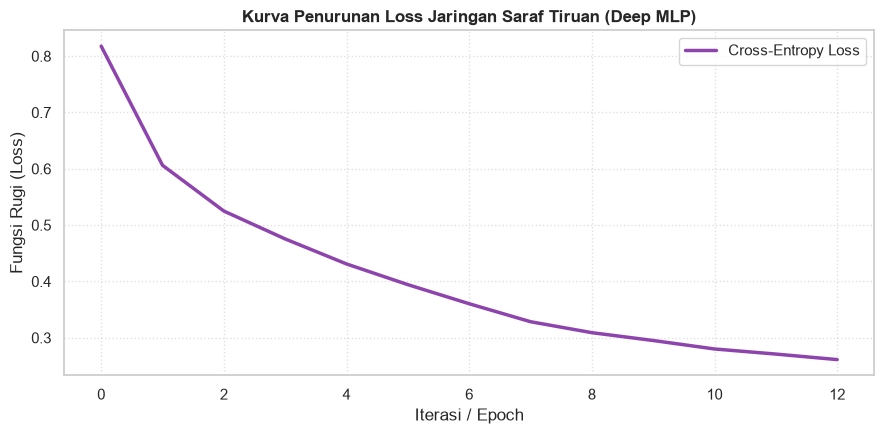

In [5]:
plt.figure(figsize=(9, 4.5))
plt.plot(mlp_clf.loss_curve_, color='#8e44ad', linewidth=2.5, label='Cross-Entropy Loss')
plt.title('Kurva Penurunan Loss Jaringan Saraf Tiruan (Deep MLP)', fontsize=12, fontweight='bold')
plt.xlabel('Iterasi / Epoch')
plt.ylabel('Fungsi Rugi (Loss)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
# Memuat data cafe untuk eksperimen JST Regresi
path_cafes = '../outputs/cafes_preprocessed.csv'
if not os.path.exists(path_cafes): path_cafes = '../dataset/cafes.csv'
df_cafes = pd.read_csv(path_cafes)

if 'price_min_imputed' not in df_cafes.columns:
    df_cafes['price_min_imputed'] = df_cafes['price_min'].fillna(df_cafes['price_min'].median())
    df_cafes['price_max_imputed'] = df_cafes['price_max'].fillna(df_cafes['price_max'].median())

fitur_reg = ['latitude', 'longitude', 'review_count', 'price_min_imputed', 'price_max_imputed']
X_reg = df_cafes[fitur_reg].values
y_reg = df_cafes['rating'].values

# Split data regresi
X_tr_reg, X_te_reg, y_tr_reg, y_te_reg = train_test_split(X_reg, y_reg, test_size=0.20, random_state=42)

# Normalisasi input
from sklearn.preprocessing import StandardScaler
sc_reg = StandardScaler()
X_tr_reg_sc = sc_reg.fit_transform(X_tr_reg)
X_te_reg_sc = sc_reg.transform(X_te_reg)

# Melatih MLP Regressor
mlp_reg = MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu', solver='adam', max_iter=200, random_state=42)
mlp_reg.fit(X_tr_reg_sc, y_tr_reg)

y_pred_reg = mlp_reg.predict(X_te_reg_sc)
mse_ann = mean_squared_error(y_te_reg, y_pred_reg)
r2_ann  = r2_score(y_te_reg, y_pred_reg)

print(f"Hasil Evaluasi JST Regressor Prediksi Rating Cafe:")
print(f"- Mean Squared Error (MSE) : {mse_ann:.4f}")
print(f"- Root MSE (RMSE)           : {np.sqrt(mse_ann):.4f} bintang")
print(f"- R-Squared (R2)            : {r2_ann:.4f}")

Hasil Evaluasi JST Regressor Prediksi Rating Cafe:
- Mean Squared Error (MSE) : 0.2516
- Root MSE (RMSE)           : 0.5016 bintang
- R-Squared (R2)            : -2.1763


D:\laragon\bin\python\python-3.13\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(



In [7]:
import joblib

os.makedirs('../outputs', exist_ok=True)
path_saved_ann = '../outputs/deep_mlp_sentiment_js13.joblib'
joblib.dump({'classifier': mlp_clf, 'regressor': mlp_reg, 'vectorizer': vec_tfidf}, path_saved_ann)
print(f"Model JST Deep MLP Classifier dan Regressor tersimpan ke: {path_saved_ann}")

Model JST Deep MLP Classifier dan Regressor tersimpan ke: ../outputs/deep_mlp_sentiment_js13.joblib
